# Titanic: логистическая регрессия и решающие деревья

### Запуск

In [34]:
%pip install numpy pandas matplotlib scikit-learn

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
)

RANDOM_STATE = 42
plt.rcParams.update({
    'figure.figsize': (10, 4),
    'axes.grid': True,
    'grid.alpha': 0.2,
    'font.size': 11,
})

<a id="task"></a>
## 1. Данные и задача

Одна строка — один пассажир Titanic. По его признакам $x$ предсказываем
`Survived`: **0 — не выжил, 1 — выжил**. Это бинарная классификация.
Модель оценивает вероятность $p(y=1\mid x)$ и переводит её в класс по порогу 0.5.

В таблице 891 пассажир.
[Источник данных](https://github.com/datasciencedojo/datasets/blob/master/titanic.csv).

In [36]:
import base64
import gzip
import io

_TITANIC_DATA = (
    "..."
)

def load_titanic():
    csv_data = gzip.decompress(base64.b64decode(_TITANIC_DATA))
    return pd.read_csv(io.BytesIO(csv_data))

In [37]:
titanic = load_titanic()
display(titanic.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 1.1. Признаки

| Столбец | Значение | Подготовка |
| :--- | :--- | :--- |
| `Survived` | Выживание | Целевая переменная |
| `Pclass` | Класс билета: 1, 2, 3 | Числовой признак |
| `Sex` | Пол | `female → 0`, `male → 1` |
| `Age` | Возраст в годах | Пропуски заменяем медианой train |
| `SibSp` | Братья, сёстры и супруги на борту | Числовой признак |
| `Parch` | Родители и дети на борту | Числовой признак |
| `Fare` | Стоимость проезда | Числовой признак; пропуски — медиана train |
| `Embarked` | Порт посадки: C — Cherbourg, Q — Queenstown, S — Southampton | Пропуски — мода train; one-hot для обеих моделей |

Используем семь исходных признаков. Числовое кодирование `Pclass` предполагает
линейный вклад класса билета в логистической регрессии; one-hot сняло бы это ограничение.

In [38]:
titanic.info()
display(titanic.isna().sum().rename('Пропусков').to_frame())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,Пропусков
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


<a id="preprocessing"></a>
## 2. Предобработка

### 2.1. Разделение данных

| Часть | Доля | Назначение |
| :--- | ---: | :--- |
| `train` | 60% | Обучение моделей и преобразований признаков |
| `validation` | 20% | Выбор гиперпараметров |
| `test` | 20% | Итоговая оценка качества |

`stratify=y` сохраняет близкие доли классов, `random_state=42` фиксирует разбиение.
Медианы, моду, кодировщики и масштабы признаков обучаем **только по train**.

In [39]:
NUMERIC_FEATURES = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']
CATEGORICAL_FEATURES = ['Embarked']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
X = titanic[FEATURES].copy()
X['Sex'] = X['Sex'].map({'female': 0, 'male': 1})
y = titanic['Survived'].astype(int)

X_trainval_raw, X_test_raw, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE,
)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_trainval_raw, y_trainval, test_size=0.25,
    stratify=y_trainval, random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    'Выборка': ['train', 'validation', 'test'],
    'Объектов': [len(y_train), len(y_val), len(y_test)],
    'Доля данных': [len(y_train) / len(y), len(y_val) / len(y), len(y_test) / len(y)],
})
display(split_summary.round(3))
print(f'Доля выживших в train: {y_train.mean():.3f}')

,Выборка,Объектов,Доля данных
0,train,534,0.599
1,validation,178,0.200
2,test,179,0.201


Доля выживших в train: 0.384


### 2.2. Пропуски

Числовые пропуски заменяем медианами, пропуски `Embarked` — самым частым портом
(модой). `fit` оценивает эти значения по train, `transform` применяет их к validation.

In [40]:
imputer = SimpleImputer(strategy='median')
X_train_num = pd.DataFrame(
    imputer.fit_transform(X_train_raw[NUMERIC_FEATURES]),
    columns=NUMERIC_FEATURES, index=X_train_raw.index,
)
X_val_num = pd.DataFrame(
    imputer.transform(X_val_raw[NUMERIC_FEATURES]),
    columns=NUMERIC_FEATURES, index=X_val_raw.index,
)

category_imputer = SimpleImputer(strategy='most_frequent')
X_train_cat = pd.DataFrame(
    category_imputer.fit_transform(X_train_raw[CATEGORICAL_FEATURES]),
    columns=CATEGORICAL_FEATURES, index=X_train_raw.index,
)
X_val_cat = pd.DataFrame(
    category_imputer.transform(X_val_raw[CATEGORICAL_FEATURES]),
    columns=CATEGORICAL_FEATURES, index=X_val_raw.index,
)

display(pd.Series(imputer.statistics_, index=NUMERIC_FEATURES, name='Медиана train').to_frame())
print('Мода Embarked в train:', category_imputer.statistics_[0])

,Медиана train
Pclass,3.0000
Sex,1.0000
Age,29.0000
SibSp,0.0000
Parch,0.0000
Fare,14.4542


Мода Embarked в train: S


### 2.3. Кодирование Embarked

`OneHotEncoder` заменяет порт индикаторами: 1 — пассажир сел в этом порту, 0 — нет.

**Логистическая регрессия:** `drop='first'` оставляет C базовой категорией.
Столбцы `Embarked_Q` и `Embarked_S` показывают отличие от C; для C оба равны нулю.
Так нет линейной зависимости между всеми индикаторами и свободным членом.

**Дерево:** сохраняем все три столбца — `Embarked_C`, `Embarked_Q`, `Embarked_S`.
Каждый порт можно отделить одним разбиением. Например, `Embarked_C ≤ 0.5`
означает «порт не C». Произвольный числовой порядок портов не задаётся.

In [41]:
onehot = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
X_train_ohe = onehot.fit_transform(X_train_cat)
X_val_ohe = onehot.transform(X_val_cat)
OHE_FEATURES = onehot.get_feature_names_out(CATEGORICAL_FEATURES).tolist()
LR_FEATURES = NUMERIC_FEATURES + OHE_FEATURES

tree_onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_tree_ohe = tree_onehot.fit_transform(X_train_cat)
X_val_tree_ohe = tree_onehot.transform(X_val_cat)
TREE_OHE_FEATURES = tree_onehot.get_feature_names_out(CATEGORICAL_FEATURES).tolist()
TREE_FEATURES = NUMERIC_FEATURES + TREE_OHE_FEATURES
X_train_tree = pd.DataFrame(
    np.column_stack([X_train_num, X_train_tree_ohe]),
    columns=TREE_FEATURES, index=X_train_raw.index,
)
X_val_tree = pd.DataFrame(
    np.column_stack([X_val_num, X_val_tree_ohe]),
    columns=TREE_FEATURES, index=X_val_raw.index,
)

ports = pd.DataFrame({'Embarked': tree_onehot.categories_[0]})
encoding_example = ports.copy()
encoding_example[TREE_OHE_FEATURES] = tree_onehot.transform(ports).astype(int)
display(encoding_example)

,Embarked,Embarked_C,Embarked_Q,Embarked_S
0,C,1,0,0
1,Q,0,1,0
2,S,0,0,1


### 2.4. Распределения и корреляции

Исследуем обучающую часть. Корреляции считаем для шести числовых признаков
и целевой переменной. Корреляция не доказывает причинность.

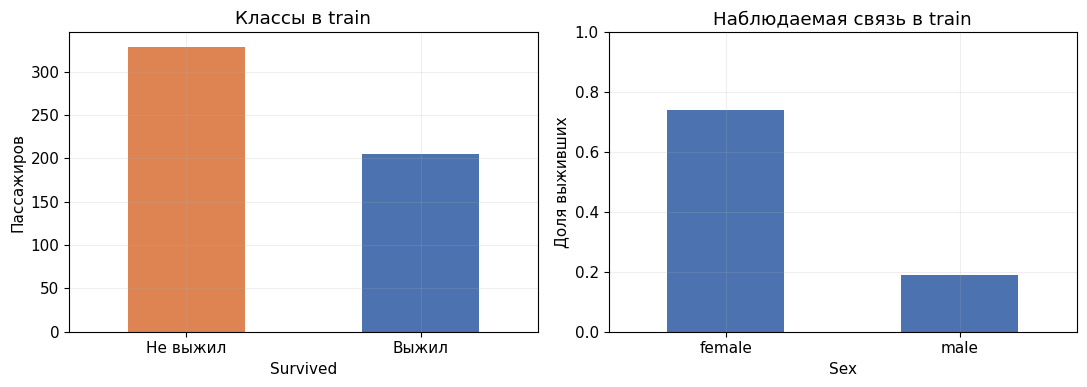

,Pclass,Sex,Age,SibSp,Parch,Fare,Survived
Pclass,1.00,0.12,-0.33,0.11,0.02,-0.57,-0.34
Sex,0.12,1.00,0.08,-0.07,-0.28,-0.20,-0.54
Age,-0.33,0.08,1.00,-0.23,-0.16,0.13,-0.08
SibSp,0.11,-0.07,-0.23,1.00,0.38,0.14,-0.02
Parch,0.02,-0.28,-0.16,0.38,1.00,0.22,0.12
Fare,-0.57,-0.20,0.13,0.14,0.22,1.00,0.29
Survived,-0.34,-0.54,-0.08,-0.02,0.12,0.29,1.00


In [42]:
train_eda = X_train_num.assign(Survived=y_train)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y_train.value_counts().sort_index().plot.bar(
    ax=axes[0], color=['#dd8452', '#4c72b0'], rot=0,
)
axes[0].set(xticklabels=['Не выжил', 'Выжил'], ylabel='Пассажиров', title='Классы в train')
train_eda.groupby('Sex')['Survived'].mean().plot.bar(ax=axes[1], color='#4c72b0', rot=0)
axes[1].set(xticklabels=['female', 'male'], ylabel='Доля выживших',
            xlabel='Sex', title='Наблюдаемая связь в train', ylim=(0, 1))
plt.tight_layout()
plt.show()
display(train_eda.corr().round(2))

### 2.5. Масштабирование

Для градиентного спуска приводим числовые признаки к сопоставимому масштабу:

$$x'_j=\frac{x_j-\mu_j}{\sigma_j}.$$

Среднее $\mu_j$ и стандартное отклонение $\sigma_j$ оцениваем по train.
One-hot-столбцы оставляем равными 0 или 1. Добавляем столбец единиц
для свободного члена $w_0$. Признаки дерева не масштабируем.

In [43]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_num)
X_val_scaled = scaler.transform(X_val_num)

def add_bias(values):
    values = np.asarray(values, dtype=float)
    return np.column_stack([np.ones(len(values)), values])

X_train_lr = add_bias(np.column_stack([X_train_scaled, X_train_ohe]))
X_val_lr = add_bias(np.column_stack([X_val_scaled, X_val_ohe]))
y_train_np = y_train.to_numpy(dtype=float)
y_val_np = y_val.to_numpy(dtype=float)

display(pd.DataFrame(X_train_lr, columns=['bias'] + LR_FEATURES).head().round(3))
print('Матрица train:', X_train_lr.shape)

,bias,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,1.0,-1.571,-1.351,0.693,0.468,-0.472,0.535,0.0,1.0
1,1.0,0.833,0.740,-1.977,2.328,1.861,-0.073,0.0,1.0
2,1.0,0.833,0.740,-0.909,0.468,0.694,-0.239,0.0,1.0
3,1.0,-1.571,-1.351,1.837,0.468,-0.472,0.611,0.0,0.0
4,1.0,0.833,-1.351,0.693,0.468,5.359,0.001,0.0,1.0


Матрица train: (534, 9)


<a id="logreg"></a>
## 3. Логистическая регрессия

### 3.1. От признаков к вероятности

Линейная оценка и сигмоида:

$$z(x)=w_0+\sum_{j=1}^{d}w_jx'_j=\langle w,\widetilde{x}\rangle,
\qquad p(y=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}.$$

Здесь $\widetilde{x}=(1,x'_1,\ldots,x'_d)$.
Предсказываем класс 1 при $p\geq0.5$, иначе 0.
Граница решения $z=0$ линейна в пространстве признаков.

In [44]:
def sigmoid(z):
    # logaddexp обеспечивает устойчивость и для больших по модулю z.
    return np.exp(-np.logaddexp(0.0, -np.asarray(z)))

def predict_proba_numpy(weights, design_matrix):
    return sigmoid(design_matrix @ weights)

def predict_numpy(weights, design_matrix, threshold=0.5):
    return (predict_proba_numpy(weights, design_matrix) >= threshold).astype(int)

### 3.2. Функция потерь

Для меток $y_i\in\{0,1\}$ минимизируем среднюю бинарную кросс-энтропию:

$$L(w)=-\frac1n\sum_{i=1}^n\left[\frac{#cats}{#dogs} y_i\log p_i + (1-y_i)\log(1-p_i)\right].$$

Уверенная ошибка даёт большую потерю. Численно устойчивая запись через $z_i$:

$$L(w)=\frac1n\sum_i\left[\log(1+e^{z_i})-y_i z_i\right].$$

В коде $\log(1+e^z)$ вычисляется функцией `np.logaddexp(0, z)`.

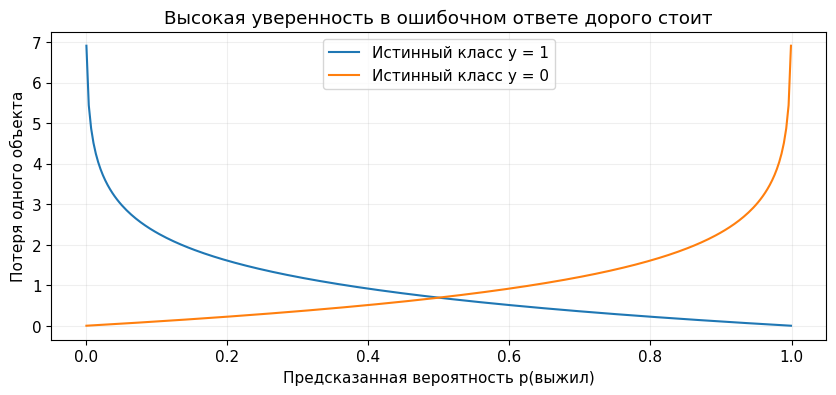

In [45]:
def logistic_loss(weights, design_matrix, target):
    logits = design_matrix @ weights
    return np.mean(np.logaddexp(0.0, logits) - target * logits)

def logistic_gradient(weights, design_matrix, target):
    probabilities = predict_proba_numpy(weights, design_matrix)
    return design_matrix.T @ (probabilities - target) / len(target)

p_grid = np.linspace(0.001, 0.999, 300)
plt.plot(p_grid, -np.log(p_grid), label='Истинный класс y = 1')
plt.plot(p_grid, -np.log(1 - p_grid), label='Истинный класс y = 0')
plt.xlabel('Предсказанная вероятность p(выжил)')
plt.ylabel('Потеря одного объекта')
plt.title('Высокая уверенность в ошибочном ответе дорого стоит')
plt.legend()
plt.show()

### 3.3. Градиентный спуск

$$\nabla_w L=\frac1n X^\top(p-y),\qquad
w\leftarrow w-\eta\nabla_w L.$$

$X$ — матрица признаков со столбцом единиц, $\eta$ — темп обучения.
Начальные веса — нули, поэтому начальные вероятности равны 0.5.
Выполним 4000 шагов с $\eta=0.1$, без штрафа на веса.

Потеря train: 0.6931 → 0.4351


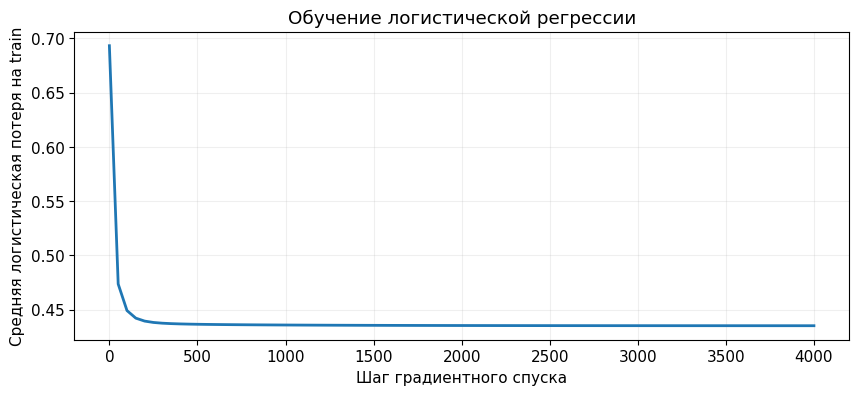

In [46]:
LEARNING_RATE = 0.1
N_STEPS = 4000

def fit_logistic_numpy(design_matrix, target, learning_rate=LEARNING_RATE, n_steps=N_STEPS):
    target = np.asarray(target, dtype=float)
    weights = np.zeros(design_matrix.shape[1], dtype=float)
    history = []
    for step in range(n_steps + 1):
        if step % 50 == 0 or step == n_steps:
            history.append({'step': step, 'loss': logistic_loss(weights, design_matrix, target)})
        if step < n_steps:
            weights -= learning_rate * logistic_gradient(weights, design_matrix, target)
    return weights, pd.DataFrame(history)

weights_lr, loss_history = fit_logistic_numpy(X_train_lr, y_train_np)
print(f'Потеря train: {loss_history.loss.iloc[0]:.4f} → {loss_history.loss.iloc[-1]:.4f}')
plt.plot(loss_history['step'], loss_history['loss'], linewidth=2)
plt.xlabel('Шаг градиентного спуска')
plt.ylabel('Средняя логистическая потеря на train')
plt.title('Обучение логистической регрессии')
plt.show()

### 3.4. Веса и предсказания

$$\log\frac{p}{1-p}=w_0+\sum_j w_jx'_j.$$

При фиксированных остальных признаках положительный вес увеличивает вероятность
выживания, отрицательный уменьшает. Единица стандартизованного признака — одно
стандартное отклонение train. Вес `Embarked_Q` или `Embarked_S` — изменение
логарифма шансов относительно порта C при прочих равных.
Вес описывает зависимость, а не причинное влияние.

In [47]:
display(pd.Series(weights_lr, index=['bias'] + LR_FEATURES, name='Вес').to_frame().round(3))
proba_lr_val = predict_proba_numpy(weights_lr, X_val_lr)
examples_lr = X_val_raw.head(8).copy()
examples_lr['y_true'] = y_val.head(8)
examples_lr['p_survived'] = proba_lr_val[:8]
examples_lr['y_pred'] = (proba_lr_val[:8] >= 0.5).astype(int)
display(examples_lr.round(3))

,Вес
bias,-0.554
Pclass,-0.996
Sex,-1.275
Age,-0.544
SibSp,-0.210
Parch,-0.058
Fare,0.173
Embarked_Q,0.705
Embarked_S,-0.229


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,y_true,p_survived,y_pred
320,3,1,22.0,0,0,7.250,S,0,0.100,0
131,3,1,20.0,0,0,7.050,S,0,0.108,0
316,2,0,24.0,1,0,26.000,S,1,0.812,1
89,3,1,24.0,0,0,8.050,S,0,0.093,0
154,3,1,NaN,0,0,7.312,S,0,0.077,0
294,3,1,24.0,0,0,7.896,S,0,0.093,0
425,3,1,NaN,0,0,7.250,S,0,0.077,0
306,1,0,NaN,0,0,110.883,C,1,0.961,1


### 3.5. Метрики качества

Положительный класс — «выжил».

| | Предсказали 0 | Предсказали 1 |
| :--- | :--- | :--- |
| **Истинный класс 0** | TN | FP |
| **Истинный класс 1** | FN | TP |

$$\mathrm{Accuracy}=\frac{TP+TN}{n},\quad
\mathrm{Precision}=\frac{TP}{TP+FP},\quad
\mathrm{Recall}=\frac{TP}{TP+FN},\quad
F_1=\frac{2TP}{2TP+FP+FN}.$$

- **Accuracy** — доля верных ответов.
- **Precision** — доля действительно выживших среди предсказанных выживших.
- **Recall** — доля найденных выживших.
- **F1** — гармоническое среднее precision и recall.
- **ROC-AUC** — качество ранжирования по вероятностям; 0.5 соответствует случайному
  ранжированию. ROC показывает зависимость $TPR=TP/(TP+FN)$ от $FPR=FP/(FP+TN)$
  при изменении порога.

Сравним с константной моделью: всем пассажирам назначается вероятность,
равная доле выживших в train. Метрики с нулевым знаменателем считаем равными нулю.

In [48]:
def metric_row(name, y_true, proba):
    pred = (np.asarray(proba) >= 0.5).astype(int)
    return {
        'Модель': name,
        'Accuracy': accuracy_score(y_true, pred),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'F1': f1_score(y_true, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, proba),
    }

lr_validation_metrics = pd.DataFrame([
    metric_row('Логрег - train', y_train, predict_proba_numpy(weights_lr, X_train_lr)),
    metric_row('Логрег - validation', y_val, proba_lr_val),
]).set_index('Модель')
display(lr_validation_metrics.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Логрег - train,0.801,0.751,0.722,0.736,0.859
Логрег - validation,0.798,0.758,0.691,0.723,0.856


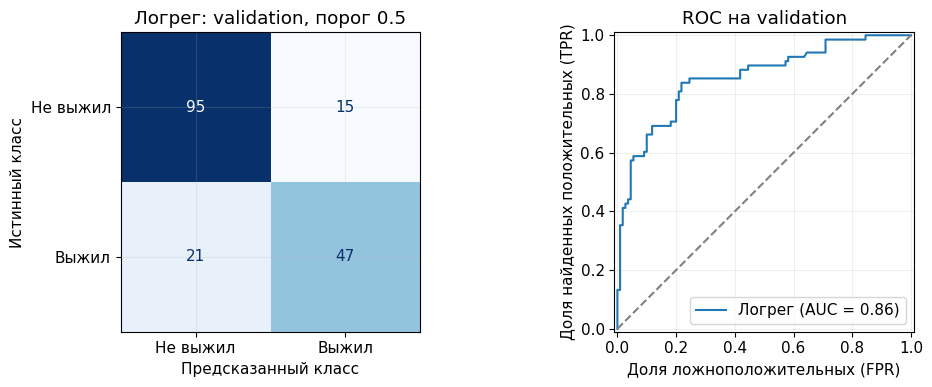

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_val, (proba_lr_val >= 0.5).astype(int), labels=[0, 1],
    display_labels=['Не выжил', 'Выжил'], cmap='Blues', colorbar=False, ax=axes[0],
)
axes[0].set(title='Логрег: validation, порог 0.5', xlabel='Предсказанный класс', ylabel='Истинный класс')
RocCurveDisplay.from_predictions(y_val, proba_lr_val, name='Логрег', ax=axes[1])
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set(title='ROC на validation', xlabel='Доля ложноположительных (FPR)',
            ylabel='Доля найденных положительных (TPR)')
plt.tight_layout()
plt.show()

<a id="trees"></a>

## 4. Как устроено решающее дерево

**Решающее дерево** последовательно проверяет условия вида «`Age ≤ порог`».
Условие выполнено — объект идёт налево, иначе — направо, пока не попадёт
в **лист**. Доли классов в листе задают вероятности, самый частый класс — ответ.

Семь исходных признаков после one-hot дают девять столбцов: шесть числовых
и три индикатора портов. Разбиение данных остаётся прежним. Масштабирование дереву
обычно не нужно: оно сохраняет порядок значений и возможные разбиения.
Пороги оставляем в исходных единицах.

### Посмотрим на небольшое дерево

Дерево ограничено двумя уровнями разбиений. В узлах указаны условие,
неоднородность `gini`, число обучающих объектов `samples`, распределение
классов `value` (численности или доли, в зависимости от версии scikit-learn)
и предсказываемый класс. Кодировка: `Sex = 0` — женщина, `Sex = 1` — мужчина.
`Embarked_C`, `Embarked_Q`, `Embarked_S` равны 1 для соответствующего порта и 0 иначе.

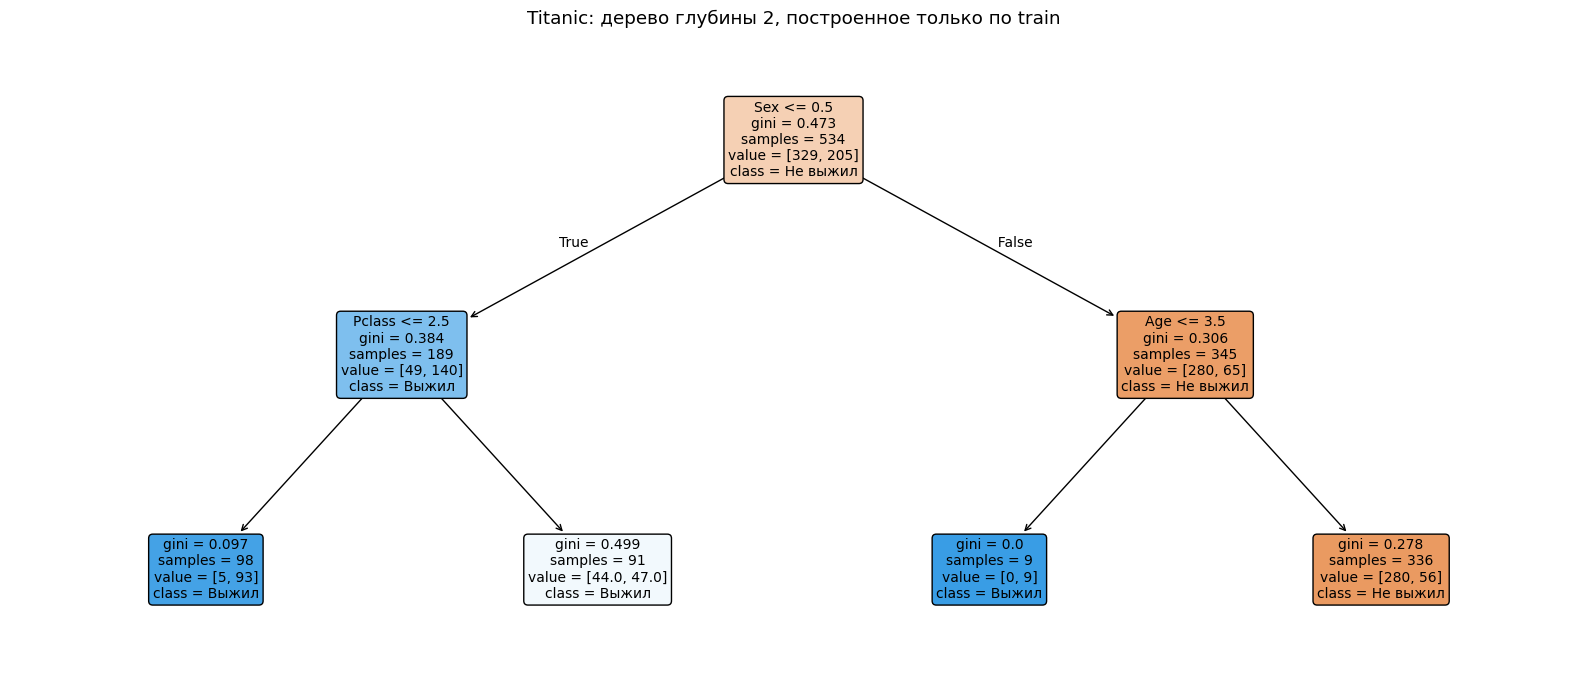

In [50]:
tree_small = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
tree_small.fit(X_train_tree, y_train)

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    tree_small,
    feature_names=X_train_tree.columns.tolist(),
    class_names=["Не выжил", "Выжил"],
    filled=True,
    rounded=True,
    precision=3,
    fontsize=10,
    ax=ax,
)
ax.set_title("Titanic: дерево глубины 2, построенное только по train")
plt.tight_layout()
plt.show()

### Как выбрать признак и порог

Для признака $j$ перебираем пороги между соседними различными значениями
в текущем узле $R$:

$$R_L=\{i\in R:x_{ij}\le t\},\qquad R_R=\{i\in R:x_{ij}>t\}.$$

Выбираем максимальное уменьшение неоднородности $H$:

$$Q(R,j,t)=H(R)-\frac{|R_L|}{|R|}H(R_L)-\frac{|R_R|}{|R|}H(R_R).$$

Веса учитывают размеры дочерних узлов. Это локальный выбор,
без оценки будущих ветвей.

### Джини и энтропия

Для долей классов $p_k$:

$$H_{\mathrm{Gini}}=1-\sum_k p_k^2,\qquad
H_{\mathrm{entropy}}=-\sum_k p_k\log p_k.$$

В бинарной задаче с долей выживших $p$:

$$H_{\mathrm{Gini}}=2p(1-p),\qquad
H_{\mathrm{entropy}}=-p\log_2p-(1-p)\log(1-p).$$

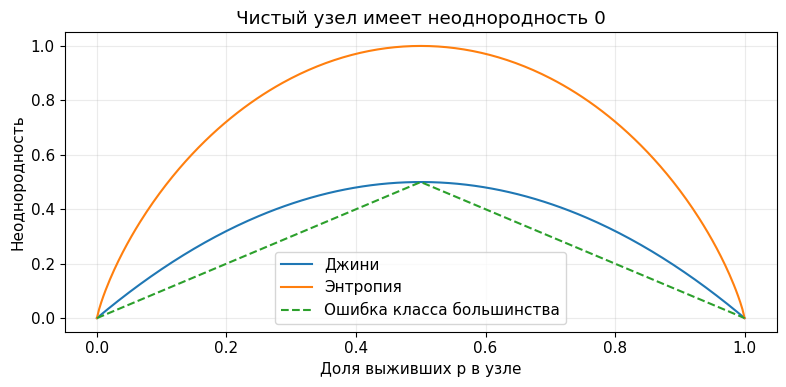

In [51]:
probabilities = np.linspace(0, 1, 301)
gini_curve = 2 * probabilities * (1 - probabilities)
entropy_curve = np.zeros_like(probabilities)
interior = (probabilities > 0) & (probabilities < 1)
p_interior = probabilities[interior]
entropy_curve[interior] = (
    -p_interior * np.log2(p_interior)
    -(1 - p_interior) * np.log2(1 - p_interior)
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(probabilities, gini_curve, label="Джини")
ax.plot(probabilities, entropy_curve, label="Энтропия")
ax.plot(probabilities, np.minimum(probabilities, 1 - probabilities),
        linestyle="--", label="Ошибка класса большинства")
ax.set(xlabel="Доля выживших p в узле", ylabel="Неоднородность",
       title="Чистый узел имеет неоднородность 0")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Найдём первое разбиение вручную

Перебираем признаки и пороги на **train**, вычисляем взвешенный Джини
и выигрыш. Лучший выигрыш сравниваем с деревом глубины 1 — *пнём*
(`stump`) из scikit-learn. При равном выигрыше признаки могут различаться;
пороги — немного отличаться из-за преобразования в `float32`.

In [52]:
train_targets_array = np.asarray(y_train, dtype=int)
root_probability = train_targets_array.mean()
root_gini = 2 * root_probability * (1 - root_probability)
split_records = []

for feature in X_train_tree.columns:
    feature_values = X_train_tree[feature].to_numpy(dtype=float)
    unique_values = np.unique(feature_values)
    thresholds = unique_values[:-1] + np.diff(unique_values) / 2
    for threshold in thresholds:
        left = feature_values <= threshold
        n_left, n_right = int(left.sum()), int((~left).sum())
        p_left = train_targets_array[left].mean()
        p_right = train_targets_array[~left].mean()
        gini_left = 2 * p_left * (1 - p_left)
        gini_right = 2 * p_right * (1 - p_right)
        weighted_gini = (n_left * gini_left + n_right * gini_right) / len(left)
        split_records.append({
            "Признак": feature, "Порог": threshold,
            "n слева": n_left, "n справа": n_right,
            "p слева": p_left, "p справа": p_right,
            "Взвешенный Джини": weighted_gini,
            "Выигрыш": root_gini - weighted_gini,
        })

split_table = pd.DataFrame(split_records).sort_values("Выигрыш", ascending=False)
display(split_table.head(10).round(5))

tree_stump = DecisionTreeClassifier(max_depth=1, criterion="gini", random_state=RANDOM_STATE)
tree_stump.fit(X_train_tree, y_train)
stump_structure = tree_stump.tree_
left_node, right_node = stump_structure.children_left[0], stump_structure.children_right[0]
stump_weighted_gini = (
    stump_structure.n_node_samples[left_node] * stump_structure.impurity[left_node]
    + stump_structure.n_node_samples[right_node] * stump_structure.impurity[right_node]
) / stump_structure.n_node_samples[0]
stump_gain = stump_structure.impurity[0] - stump_weighted_gini
stump_feature = X_train_tree.columns[stump_structure.feature[0]]
stump_threshold = stump_structure.threshold[0]
manual_best_gain = split_table["Выигрыш"].max()

print(f"Джини исходного узла: {root_gini:.6f}")
print(f"Лучший выигрыш вручную: {manual_best_gain:.6f}")
print(f"scikit-learn: {stump_feature} ≤ {stump_threshold:.6f}; выигрыш {stump_gain:.6f}")

,Признак,Порог,n слева,n справа,p слева,p справа,Взвешенный Джини,Выигрыш
2,Sex,0.50000,189,345,0.74074,0.18841,0.33352,0.13952
236,Fare,52.27710,446,88,0.31390,0.73864,0.42338,0.04966
0,Pclass,1.50000,128,406,0.66406,0.29557,0.42355,0.04949
170,Fare,15.64585,291,243,0.24399,0.55144,0.42616,0.04688
235,Fare,51.93125,442,92,0.31448,0.71739,0.42674,0.04630
234,Fare,50.93125,440,94,0.31364,0.71277,0.42683,0.04621
231,Fare,48.20000,436,98,0.31193,0.70408,0.42695,0.04609
169,Fare,15.52500,290,244,0.24483,0.54918,0.42707,0.04597
237,Fare,52.82710,449,85,0.31849,0.72941,0.42784,0.04520
233,Fare,49.75210,439,95,0.31435,0.70526,0.42834,0.04470


Джини исходного узла: 0.473039
Лучший выигрыш вручную: 0.139519
scikit-learn: Sex ≤ 0.500000; выигрыш 0.139519


### От пня к дереву: жадный алгоритм

1. Выбрать лучшее разбиение текущего узла.
2. Повторить поиск в каждом дочернем узле.
3. Остановиться по ограничениям или при отсутствии допустимого полезного
   разбиения; сохранить доли классов в листьях.

Алгоритм **жадный**: лучший локальный шаг не гарантирует лучшего дерева.
Объекты с одинаковыми признаками и разными метками разделить невозможно.

<a id="overfitting"></a>

## 5. Переобучение и настройка дерева

**Переобучение:** дерево запоминает отдельные объекты, улучшая train,
но не качество на новых данных. **Недообучение:** слишком простая модель
плохо работает уже на train.

Параметры выбираем по validation; test используем только для итоговой оценки.

### Небольшое дерево и дерево без ограничения глубины

Сравниваем `tree_small` (`max_depth=2`) и `tree_deep` без ограничения
глубины на всех девяти столбцах после кодирования: метрики train/validation, глубину и число листьев.

In [53]:
tree_deep = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_deep.fit(X_train_tree, y_train)

def tree_predict_labels(model, features):
    # Единый порог семинара, включая случай точного p = 0.5.
    return (model.predict_proba(features)[:, 1] >= 0.5).astype(int)

def tree_metric_record(model, model_name, split_name, features, labels):
    row = metric_row(model_name, labels, model.predict_proba(features)[:, 1])
    row.update({
        "Выборка": split_name,
        "Глубина": model.get_depth(),
        "Листьев": model.get_n_leaves(),
    })
    return row

initial_tree_metrics = []
for name, model in [("Дерево, глубина 2", tree_small), ("Дерево без ограничений", tree_deep)]:
    initial_tree_metrics.append(tree_metric_record(model, name, "train", X_train_tree, y_train))
    initial_tree_metrics.append(tree_metric_record(model, name, "validation", X_val_tree, y_val))
display(pd.DataFrame(initial_tree_metrics).round(4))

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC,Выборка,Глубина,Листьев
0,"Дерево, глубина 2",0.8034,0.7525,0.7268,0.7395,0.8208,train,2,4
1,"Дерево, глубина 2",0.8090,0.7429,0.7647,0.7536,0.8316,validation,2,4
2,Дерево без ограничений,0.9831,0.9623,0.9951,0.9784,0.9994,train,15,121
3,Дерево без ограничений,0.7921,0.7123,0.7647,0.7376,0.7864,validation,15,121


### Границы решений на плоскости Age / Fare

Это отдельные модели на **двух признаках**, их метрики отличаются от
метрик основного дерева с девятью столбцами после кодирования. Разбиения образуют прямоугольные области.

Ось `Fare` ограничена 98-м перцентилем train только на рисунке;
обучение и метрики используют все объекты. Кружки — train,
крестики — validation, цвет — истинный класс.

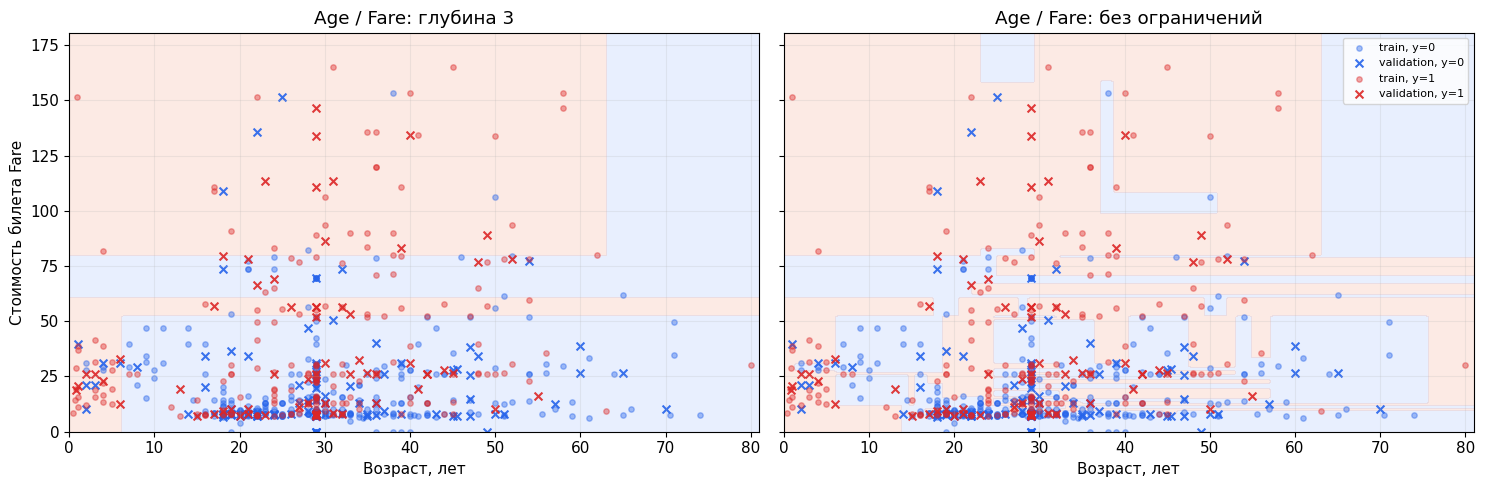

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC,Выборка,Глубина,Листьев
0,Age / Fare: глубина 3,0.7303,0.8588,0.3561,0.5034,0.7338,train,3,8
1,Age / Fare: глубина 3,0.6910,0.6857,0.3529,0.4660,0.6957,validation,3,8
2,Age / Fare: без ограничений,0.9625,0.9263,0.9805,0.9526,0.9968,train,22,167
3,Age / Fare: без ограничений,0.6573,0.5479,0.5882,0.5674,0.6471,validation,22,167


In [54]:
X_train_2d = X_train_tree[["Age", "Fare"]].copy()
X_val_2d = X_val_tree[["Age", "Fare"]].copy()
tree_2d_small = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree_2d_deep = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_2d_small.fit(X_train_2d, y_train)
tree_2d_deep.fit(X_train_2d, y_train)

age_limits = (max(0, X_train_2d["Age"].min() - 1), X_train_2d["Age"].max() + 1)
fare_limits = (0, X_train_2d["Fare"].quantile(0.98))
age_grid, fare_grid = np.meshgrid(
    np.linspace(*age_limits, 220), np.linspace(*fare_limits, 220)
)
grid_2d = pd.DataFrame({"Age": age_grid.ravel(), "Fare": fare_grid.ravel()})
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True, sharey=True)
two_dimensional_metrics = []
for ax, name, model in zip(
    axes, ["Age / Fare: глубина 3", "Age / Fare: без ограничений"],
    [tree_2d_small, tree_2d_deep],
):
    decision = tree_predict_labels(model, grid_2d).reshape(age_grid.shape)
    ax.contourf(age_grid, fare_grid, decision, levels=[-0.5, 0.5, 1.5],
                cmap="coolwarm", alpha=0.20)
    for label, color in [(0, "#2563eb"), (1, "#dc2626")]:
        train_mask = np.asarray(y_train) == label
        val_mask = np.asarray(y_val) == label
        ax.scatter(X_train_2d.loc[train_mask, "Age"], X_train_2d.loc[train_mask, "Fare"],
                   c=color, s=15, alpha=0.4, label=f"train, y={label}")
        ax.scatter(X_val_2d.loc[val_mask, "Age"], X_val_2d.loc[val_mask, "Fare"],
                   c=color, marker="x", s=32, alpha=0.9, label=f"validation, y={label}")
    ax.set(xlim=age_limits, ylim=fare_limits, xlabel="Возраст, лет", title=name)
    for split_name, features, labels in [
        ("train", X_train_2d, y_train), ("validation", X_val_2d, y_val)
    ]:
        two_dimensional_metrics.append(tree_metric_record(model, name, split_name, features, labels))
axes[0].set_ylabel("Стоимость билета Fare")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()
display(pd.DataFrame(two_dimensional_metrics).round(4))

### Как влияет максимальная глубина

Для полного набора признаков меняем `max_depth` от 1 до 20, сохраняя train/validation.
Рост accuracy на train при стагнации или снижении accuracy на validation
указывает на переобучение. Оцениваем и разрыв кривых, и уровень validation;
на небольшой выборке возможны колебания.

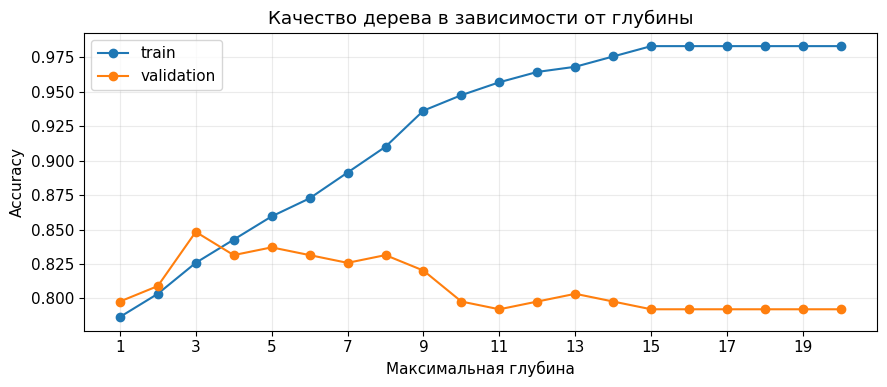

,max_depth,train,validation,Листьев
0,1,0.7865,0.7978,2
1,2,0.8034,0.8090,4
2,3,0.8258,0.8483,7
3,4,0.8427,0.8315,12
4,5,0.8596,0.8371,19
5,6,0.8727,0.8315,30
6,7,0.8914,0.8258,43
7,8,0.9101,0.8315,58
8,9,0.9363,0.8202,74
9,10,0.9476,0.7978,86


In [62]:
depth_records = []
for depth in range(1, 21):
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    candidate.fit(X_train_tree, y_train)
    depth_records.append({
        "max_depth": depth,
        "train": accuracy_score(y_train, tree_predict_labels(candidate, X_train_tree)),
        "validation": accuracy_score(y_val, tree_predict_labels(candidate, X_val_tree)),
        "Листьев": candidate.get_n_leaves(),
    })
depth_results = pd.DataFrame(depth_records)

fig, ax = plt.subplots(figsize=(9, 4))
for split_name in ["train", "validation"]:
    ax.plot(depth_results["max_depth"], depth_results[split_name], marker="o", label=split_name)
ax.set(xlabel="Максимальная глубина", ylabel="Accuracy",
       title="Качество дерева в зависимости от глубины", xticks=range(1, 21, 2))
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
display(depth_results.round(4))

### Ограничения на листья и другие способы регуляризации

- `min_samples_leaf` — минимальное число объектов в листе;
- `max_leaf_nodes` — максимальное число листьев;
- `min_impurity_decrease` — минимальный выигрыш, взвешенный по доле узла во всём train;
- `ccp_alpha` — штраф за сложность при обрезке дерева: больше штраф — меньше ветвей.

Ограничения роста называют *pre-pruning*, последующую обрезку — *pruning*.
Параметры выбирают по validation или кросс-валидации. Слишком сильные
ограничения ведут к недообучению. Ниже меняется только `min_samples_leaf`.

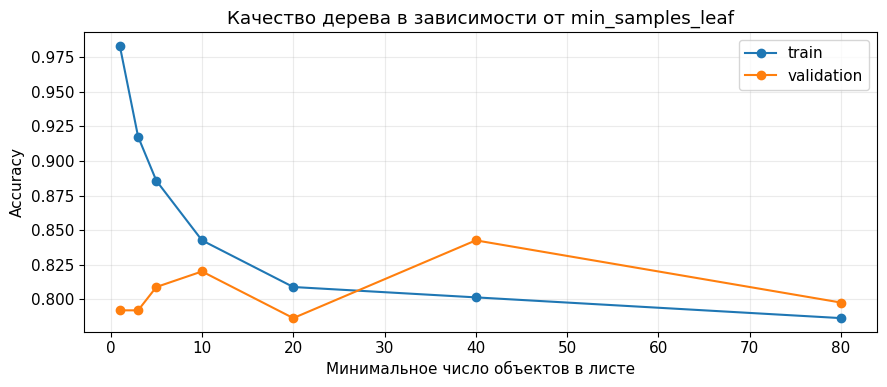

,min_samples_leaf,train,validation,Глубина,Листьев
0,1,0.9831,0.7921,15,121
1,3,0.9176,0.7921,13,76
2,5,0.8858,0.8090,11,52
3,10,0.8427,0.8202,10,33
4,20,0.8090,0.7865,8,17
5,40,0.8015,0.8427,6,10
6,80,0.7865,0.7978,3,5


In [63]:
leaf_records = []
for min_leaf in [1, 3, 5, 10, 20, 40, 80]:
    candidate = DecisionTreeClassifier(min_samples_leaf=min_leaf, random_state=RANDOM_STATE)
    candidate.fit(X_train_tree, y_train)
    leaf_records.append({
        "min_samples_leaf": min_leaf,
        "train": accuracy_score(y_train, tree_predict_labels(candidate, X_train_tree)),
        "validation": accuracy_score(y_val, tree_predict_labels(candidate, X_val_tree)),
        "Глубина": candidate.get_depth(),
        "Листьев": candidate.get_n_leaves(),
    })
leaf_results = pd.DataFrame(leaf_records)
fig, ax = plt.subplots(figsize=(9, 4))
for split_name in ["train", "validation"]:
    ax.plot(leaf_results["min_samples_leaf"], leaf_results[split_name], marker="o", label=split_name)
ax.set(xlabel="Минимальное число объектов в листе", ylabel="Accuracy",
       title="Качество дерева в зависимости от min_samples_leaf")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
display(leaf_results.round(4))

### Выберем параметры по validation

Для 35 сочетаний `max_depth` и `min_samples_leaf` с критерием `gini`
выбираем максимальную **accuracy на validation**. При равенстве предпочитаем
последовательно: меньше листьев, меньшую фактическую глубину, больший
`min_samples_leaf`, меньший `max_depth`. `None` означает неограниченную глубину.

In [64]:
depth_grid = [2, 3, 4, 5, 6, 8, None]
min_leaf_grid = [1, 3, 5, 10, 20]
tree_search_records = []
for depth in depth_grid:
    for min_leaf in min_leaf_grid:
        params = {"max_depth": depth, "min_samples_leaf": min_leaf, "criterion": "gini"}
        candidate = DecisionTreeClassifier(**params, random_state=RANDOM_STATE)
        candidate.fit(X_train_tree, y_train)
        tree_search_records.append({
            "params": params,
            "train_accuracy": accuracy_score(y_train, tree_predict_labels(candidate, X_train_tree)),
            "val_accuracy": accuracy_score(y_val, tree_predict_labels(candidate, X_val_tree)),
            "depth": candidate.get_depth(),
            "n_leaves": candidate.get_n_leaves(),
        })

ranked_tree_candidates = sorted(
    tree_search_records,
    key=lambda result: (
        -result["val_accuracy"], result["n_leaves"], result["depth"],
        -result["params"]["min_samples_leaf"],
        float("inf") if result["params"]["max_depth"] is None else result["params"]["max_depth"],
    ),
)
best_tree_params = ranked_tree_candidates[0]["params"].copy()
tree_tuned = DecisionTreeClassifier(**best_tree_params, random_state=RANDOM_STATE)
tree_tuned.fit(X_train_tree, y_train)

tree_search_table = pd.DataFrame([
    {
        "max_depth": "None" if result["params"]["max_depth"] is None else str(result["params"]["max_depth"]),
        "min_samples_leaf": result["params"]["min_samples_leaf"],
        "Accuracy train": result["train_accuracy"],
        "Accuracy validation": result["val_accuracy"],
        "Глубина": result["depth"], "Листьев": result["n_leaves"],
    }
    for result in ranked_tree_candidates
])
print("Выбранные параметры:", best_tree_params)
display(tree_search_table.head(10).round(4))

Выбранные параметры: {'max_depth': 3, 'min_samples_leaf': 5, 'criterion': 'gini'}


,max_depth,min_samples_leaf,Accuracy train,Accuracy validation,Глубина,Листьев
0,3,5,0.8258,0.8483,3,7
1,3,3,0.8258,0.8483,3,7
2,3,1,0.8258,0.8483,3,7
3,3,10,0.8240,0.8427,3,7
4,4,10,0.8240,0.8427,4,12
5,8,3,0.8914,0.8427,8,50
6,5,3,0.8558,0.8371,5,19
7,5,1,0.8596,0.8371,5,19
8,6,3,0.8670,0.8371,6,30
9,4,5,0.8333,0.8315,4,12


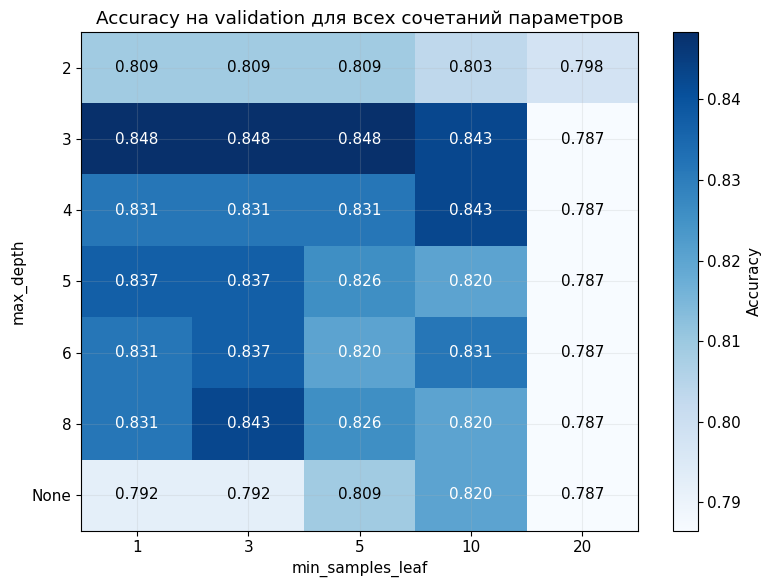

In [58]:
validation_surface = np.array([
    result["val_accuracy"] for result in tree_search_records
]).reshape(len(depth_grid), len(min_leaf_grid))

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(validation_surface, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(min_leaf_grid)), labels=min_leaf_grid)
ax.set_yticks(range(len(depth_grid)), labels=[str(depth) for depth in depth_grid])
ax.set(xlabel="min_samples_leaf", ylabel="max_depth",
       title="Accuracy на validation для всех сочетаний параметров")
midpoint = (validation_surface.min() + validation_surface.max()) / 2
for row_index in range(len(depth_grid)):
    for column_index in range(len(min_leaf_grid)):
        score = validation_surface[row_index, column_index]
        ax.text(column_index, row_index, f"{score:.3f}", ha="center", va="center",
                color="white" if score > midpoint else "black")
fig.colorbar(image, ax=ax, label="Accuracy")
plt.tight_layout()
plt.show()

### Проверим выбранное дерево по нескольким метрикам

Выбор по accuracy не гарантирует улучшения precision, recall, F1 или ROC-AUC.
Оценка победителя на validation может быть оптимистичной из-за подбора;
итоговую оценку даст test. Кросс-валидация помогает устойчивее выбрать параметры.

In [65]:
selected_tree_metrics = []
for name, model in [
    ("Дерево, глубина 2", tree_small),
    ("Дерево без ограничений", tree_deep),
    ("Дерево после настройки", tree_tuned),
]:
    for split_name, features, labels in [
        ("train", X_train_tree, y_train), ("validation", X_val_tree, y_val)
    ]:
        selected_tree_metrics.append(tree_metric_record(model, name, split_name, features, labels))
display(pd.DataFrame(selected_tree_metrics).round(4))

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC,Выборка,Глубина,Листьев
0,"Дерево, глубина 2",0.8034,0.7525,0.7268,0.7395,0.8208,train,2,4
1,"Дерево, глубина 2",0.8090,0.7429,0.7647,0.7536,0.8316,validation,2,4
2,Дерево без ограничений,0.9831,0.9623,0.9951,0.9784,0.9994,train,15,121
3,Дерево без ограничений,0.7921,0.7123,0.7647,0.7376,0.7864,validation,15,121
4,Дерево после настройки,0.8258,0.8889,0.6244,0.7335,0.8665,train,3,7
5,Дерево после настройки,0.8483,0.8868,0.6912,0.7769,0.8573,validation,3,7


### Экстраполяция

За пределами обучающего диапазона дерево направляет объект в существующий
крайний лист и сохраняет его прогноз. Оно не продолжает тренд;
в регрессионном дереве ответ в листе постоянен.

<a id="comparison"></a>
## 6. Сравнение качества на test

### 6.1. Обучение на train + validation

С выбранными настройками заново обучаем преобразования и модели на
`train + validation`. Качество оцениваем на общем test; параметры по нему не подбираем.

In [66]:
final_imputer = SimpleImputer(strategy='median')
X_trainval_num = pd.DataFrame(
    final_imputer.fit_transform(X_trainval_raw[NUMERIC_FEATURES]),
    columns=NUMERIC_FEATURES, index=X_trainval_raw.index,
)
X_test_num = pd.DataFrame(
    final_imputer.transform(X_test_raw[NUMERIC_FEATURES]),
    columns=NUMERIC_FEATURES, index=X_test_raw.index,
)
final_category_imputer = SimpleImputer(strategy='most_frequent')
X_trainval_cat = pd.DataFrame(
    final_category_imputer.fit_transform(X_trainval_raw[CATEGORICAL_FEATURES]),
    columns=CATEGORICAL_FEATURES, index=X_trainval_raw.index,
)
X_test_cat = pd.DataFrame(
    final_category_imputer.transform(X_test_raw[CATEGORICAL_FEATURES]),
    columns=CATEGORICAL_FEATURES, index=X_test_raw.index,
)

final_tree_onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_trainval_tree_ohe = final_tree_onehot.fit_transform(X_trainval_cat)
X_test_tree_ohe = final_tree_onehot.transform(X_test_cat)
FINAL_TREE_OHE_FEATURES = final_tree_onehot.get_feature_names_out(CATEGORICAL_FEATURES).tolist()
FINAL_TREE_FEATURES = NUMERIC_FEATURES + FINAL_TREE_OHE_FEATURES
X_trainval_tree = pd.DataFrame(
    np.column_stack([X_trainval_num, X_trainval_tree_ohe]),
    columns=FINAL_TREE_FEATURES, index=X_trainval_raw.index,
)
X_test_tree = pd.DataFrame(
    np.column_stack([X_test_num, X_test_tree_ohe]),
    columns=FINAL_TREE_FEATURES, index=X_test_raw.index,
)

final_onehot = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
X_trainval_ohe = final_onehot.fit_transform(X_trainval_cat)
X_test_ohe = final_onehot.transform(X_test_cat)
FINAL_LR_FEATURES = NUMERIC_FEATURES + final_onehot.get_feature_names_out(CATEGORICAL_FEATURES).tolist()
final_scaler = StandardScaler()
X_trainval_lr = add_bias(np.column_stack([
    final_scaler.fit_transform(X_trainval_num), X_trainval_ohe,
]))
X_test_lr = add_bias(np.column_stack([
    final_scaler.transform(X_test_num), X_test_ohe,
]))
final_weights_lr, final_loss_history = fit_logistic_numpy(X_trainval_lr, y_trainval)

final_small = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
final_deep = DecisionTreeClassifier(random_state=RANDOM_STATE)
final_tree = DecisionTreeClassifier(**best_tree_params, random_state=RANDOM_STATE)
for model in [final_small, final_deep, final_tree]:
    model.fit(X_trainval_tree, y_trainval)

test_probabilities = {
    'Константная модель': np.full(len(y_test), y_trainval.mean()),
    'Логистическая регрессия (NumPy)': predict_proba_numpy(final_weights_lr, X_test_lr),
    'Дерево глубины 2': final_small.predict_proba(X_test_tree)[:, 1],
    'Дерево без ограничений': final_deep.predict_proba(X_test_tree)[:, 1],
    'Дерево с выбранными настройками': final_tree.predict_proba(X_test_tree)[:, 1],
}
test_metrics = pd.DataFrame([
    metric_row(name, y_test, proba) for name, proba in test_probabilities.items()
]).set_index('Модель')
print('Настройки выбранного дерева:', best_tree_params)
print(f'Финальное обучение: {len(y_trainval)} пассажира; test: {len(y_test)} пассажиров')
display(test_metrics.round(3))

Настройки выбранного дерева: {'max_depth': 3, 'min_samples_leaf': 5, 'criterion': 'gini'}
Финальное обучение: 712 пассажира; test: 179 пассажиров


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Константная модель,0.615,0.000,0.000,0.000,0.500
Логистическая регрессия (NumPy),0.804,0.793,0.667,0.724,0.844
Дерево глубины 2,0.760,0.703,0.652,0.677,0.770
Дерево без ограничений,0.821,0.768,0.768,0.768,0.809
Дерево с выбранными настройками,0.777,0.809,0.551,0.655,0.811


### 6.2. Матрицы ошибок и ROC

Матрицы показывают соотношение FP и FN при пороге 0.5, ROC-кривые — поведение
моделей при изменении порога.

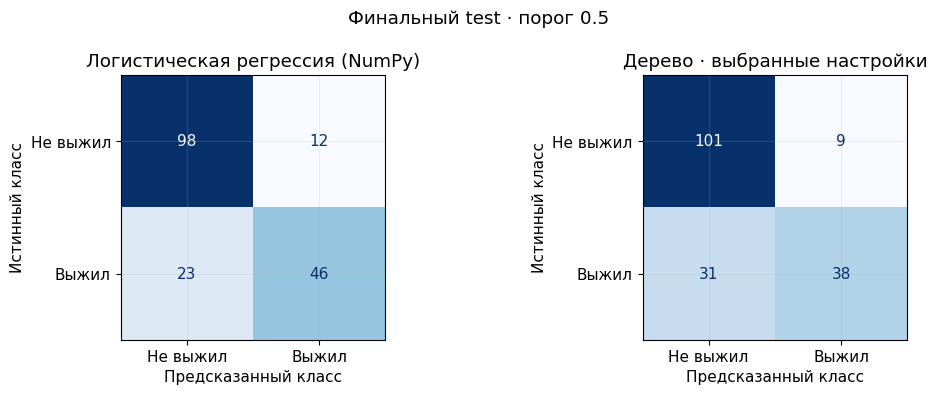

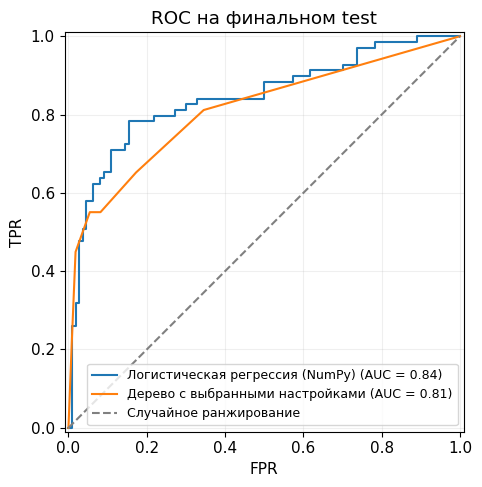

In [67]:
comparison_names = ['Логистическая регрессия (NumPy)', 'Дерево с выбранными настройками']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, comparison_names):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (test_probabilities[name] >= 0.5).astype(int), labels=[0, 1],
        display_labels=['Не выжил', 'Выжил'], cmap='Blues', colorbar=False, ax=ax,
    )
    ax.set(title=name.replace(' с выбранными настройками', ' · выбранные настройки'),
           xlabel='Предсказанный класс', ylabel='Истинный класс')
fig.suptitle('Финальный test · порог 0.5')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name in comparison_names:
    RocCurveDisplay.from_predictions(y_test, test_probabilities[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Случайное ранжирование')
ax.set(title='ROC на финальном test', xlabel='FPR', ylabel='TPR')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()